# Predicción de readmisión hospitalaria a 30 días

**Pregunta científica.** Entre adultos con cáncer dados de alta de una hospitalización, ¿la historia clínica de los 180 días previos a la admisión mejora la predicción de una nueva hospitalización durante los 30 días posteriores al alta, más allá de la edad, el sexo y el uso hospitalario previo?

El objetivo es **predictivo**, no causal. Se comparan dos regresiones logísticas (M0 y M1) y un XGBoost con configuración inicial (M2). Después se estudia una variante de M2 ajustada con una búsqueda pequeña en entrenamiento. Las cuatro evaluaciones finales usan el mismo conjunto de prueba.

Los datos son **sintéticos de Synthea** y se representaron mediante una capa OMOP mínima. Los códigos fuente se conservan, pero no se afirma un mapeo completo a los vocabularios OMOP. Por ello, ni las frecuencias clínicas ni el desempeño deben extrapolarse a pacientes reales.

## 1. Entorno y preparación

Se usa el kernel **machine_learning_env**, con Python 3.14.2. La tabla siguiente registra las versiones realmente cargadas; la versión de XGBoost se obtiene del módulo importado, compatible con las distribuciones `xgboost` y `xgboost-cpu`. Los pasos de ejecución están en `../README.md`. `../requirements.txt` conserva la referencia del entorno anterior y no describe este entorno Conda.

El notebook lee la base local en modo de solo lectura y nunca reconstruye ni modifica las tablas SQL. Cambiar versiones de XGBoost u Optuna puede cambiar el modelo seleccionado y sus resultados, aun con la misma semilla.

In [3]:
from importlib.metadata import version
from pathlib import Path
import sys
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    import optuna
    import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, __version__ as xgboost_version

pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (7, 4.6), "font.size": 10})

In [4]:
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "final_project" / "notebooks").is_dir():
        PROJECT_DIR = directory / "final_project"
        break
else:
    raise FileNotFoundError("Ejecuta el notebook desde el repositorio o final_project.")

DB_PATH = PROJECT_DIR / "data" / "omop_minimal.duckdb"
if not DB_PATH.is_file():
    raise FileNotFoundError(f"No se encontró la base analítica: {DB_PATH}")

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "readmission_30d"
M0_FEATURES = ["age", "sex", "prior_inpatient_hospitalizations_180d"]
ADDITIONAL_FEATURES = [
    "distinct_diagnoses_180d",
    "distinct_medications_180d",
    "measurement_count_180d",
]
M1_FEATURES = M0_FEATURES + ADDITIONAL_FEATURES
NUMERIC_FEATURES = [feature for feature in M1_FEATURES if feature != "sex"]
COUNT_FEATURES = [feature for feature in NUMERIC_FEATURES if feature != "age"]

print(f"Python: {sys.version.split()[0]} | {sys.executable}")
print(f"Base de datos: {DB_PATH.relative_to(PROJECT_DIR.parent)}")
display(pd.Series({
    package: xgboost_version if package == "xgboost" else version(package)
    for package in [
        "duckdb", "numpy", "pandas", "scikit-learn", "xgboost",
        "optuna", "shap", "matplotlib",
    ]
}, name="Versión").to_frame())

Python: 3.14.2 | /home/luis-enrique/miniconda3/envs/machine_learning_env/bin/python
Base de datos: final_project/data/omop_minimal.duckdb


,Versión
duckdb,2.0.0
numpy,2.4.3
pandas,2.3.3
scikit-learn,1.8.0
xgboost,3.1.2
optuna,4.6.0
shap,0.50.0
matplotlib,3.10.8


## 2. Conjunto analítico y definiciones temporales

La unidad de análisis es **un paciente por fila**, anclado en su primera hospitalización elegible. `index_admission` es el inicio de esa hospitalización y `index_discharge` es el alta: son fechas distintas. El desenlace `readmission_30d` vale 1 cuando comienza una nueva hospitalización después del alta y dentro de los 30 días siguientes.

Los predictores longitudinales se calculan en **[admisión − 180 días, admisión)**. Este límite excluye la hospitalización índice y cualquier dato registrado durante o después de ella. Las reglas clínicas y temporales residen en `../sql/`; el notebook consume `results.analytic_dataset` sin volver a definir la cohorte.

In [5]:
with duckdb.connect(str(DB_PATH), read_only=True) as connection:
    analytic_df = connection.execute(
        "SELECT * FROM results.analytic_dataset ORDER BY person_id"
    ).fetchdf()

print(f"Se cargaron {len(analytic_df):,} filas y {analytic_df.shape[1]} columnas.")
display(analytic_df.head(3).T.rename_axis("Columna"))

Se cargaron 824 filas y 11 columnas.


,0,1,2
Columna,,,
person_id,25,35,76
index_visit_id,14721,14598,2293
index_admission,2019-07-02 12:38:58,2019-05-07 23:19:32,1987-06-03 07:35:27
index_discharge,2019-07-03 12:38:58,2019-05-09 07:18:06,1987-06-05 15:34:53
age,56,61,51
sex,F,F,F
prior_inpatient_hospitalizations_180d,0,0,0
distinct_diagnoses_180d,4,2,3
distinct_medications_180d,6,0,0


## 3. Comprobaciones de la cohorte

Antes del modelado se comprueban el tamaño esperado (**824 pacientes, 85 eventos**), la unicidad de paciente y visita índice, la ausencia de valores perdidos en las columnas necesarias y la validez básica de edad, conteos y fechas. Estos controles detectan alteraciones de la tabla; **no** sustituyen una auditoría de las marcas temporales de cada registro fuente.

In [6]:
required_columns = [
    "person_id", "index_visit_id", "index_admission", "index_discharge",
    *M1_FEATURES, TARGET,
]
missing_columns = sorted(set(required_columns) - set(analytic_df.columns))
assert not missing_columns, f"Faltan columnas: {missing_columns}"
assert len(analytic_df) == 824, "Se esperaban 824 pacientes."
assert analytic_df["person_id"].is_unique, "Debe haber una fila por paciente."
assert analytic_df["index_visit_id"].is_unique, "La visita índice debe ser única."
assert not analytic_df[required_columns].isna().any().any(), "Hay valores perdidos."
assert analytic_df[TARGET].isin([0, 1]).all(), "El outcome debe ser binario."
assert analytic_df[TARGET].sum() == 85, "Se esperaban 85 readmisiones."
assert np.isfinite(analytic_df[NUMERIC_FEATURES].to_numpy()).all()
assert analytic_df["age"].ge(18).all(), "La cohorte debe incluir solo adultos."
assert analytic_df["sex"].isin(["F", "M"]).all()
assert analytic_df[COUNT_FEATURES].ge(0).all().all()
assert (analytic_df[COUNT_FEATURES] % 1 == 0).all().all()
assert (analytic_df["index_discharge"] >= analytic_df["index_admission"]).all()

cohort_summary = pd.DataFrame({
    "Pacientes": [len(analytic_df)],
    "Eventos": [int(analytic_df[TARGET].sum())],
    "Sin evento": [int(analytic_df[TARGET].eq(0).sum())],
    "Tasa de eventos (%)": [100 * analytic_df[TARGET].mean()],
    "Valores perdidos": [int(analytic_df[required_columns].isna().sum().sum())],
}, index=["Cohorte analítica"])
display(cohort_summary.round(2))
print("Comprobaciones de cohorte superadas.")

,Pacientes,Eventos,Sin evento,Tasa de eventos (%),Valores perdidos
Cohorte analítica,824,85,739,10.32,0


Comprobaciones de cohorte superadas.


## 4. Descripción de los seis predictores

| Variable del protocolo | Papel predictivo | Definición en la tabla |
|---|---|---|
| `age` | Riesgo demográfico | Edad en años al ingreso índice. |
| `sex` | Diferencias demográficas | Valor fuente F/M. |
| `prior_inpatient_hospitalizations_180d` | Utilización previa | Número de ingresos hospitalarios previos. |
| `distinct_diagnoses_180d` | Carga diagnóstica | Número de diagnósticos fuente distintos. |
| `distinct_medications_180d` | Exposición farmacológica | Número de medicamentos fuente distintos. |
| `measurement_count_180d` | Intensidad de observación | Número de mediciones numéricas de laboratorio y signos vitales. |

M0 emplea las primeras tres variables; M1 y M2 emplean las seis. Los últimos cuatro conteos utilizan la misma ventana retrospectiva de 180 días. Son **indicadores indirectos de historia y utilización**, sujetos a cómo se generan y codifican los datos sintéticos; por ejemplo, un mayor número de mediciones puede reflejar frecuencia de contacto y no solo gravedad.

In [7]:
numeric_summary = analytic_df[NUMERIC_FEATURES].describe().T.rename(columns={
    "count": "N", "mean": "Media", "std": "DE", "min": "Mínimo",
    "25%": "P25", "50%": "Mediana", "75%": "P75", "max": "Máximo",
})
numeric_summary.index.name = "Variable"
display(numeric_summary.round(2))

sex_summary = analytic_df["sex"].value_counts().sort_index().rename("Pacientes").to_frame()
sex_summary["Porcentaje"] = 100 * sex_summary["Pacientes"] / len(analytic_df)
sex_summary.index.name = "Sexo (valor fuente)"
display(sex_summary.round(2))

,N,Media,DE,Mínimo,P25,Mediana,P75,Máximo
Variable,,,,,,,,
age,824.0,60.54,10.90,21.0,51.0,61.0,68.0,98.0
prior_inpatient_hospitalizations_180d,824.0,0.03,0.23,0.0,0.0,0.0,0.0,3.0
distinct_diagnoses_180d,824.0,3.73,2.78,0.0,2.0,3.0,5.0,14.0
distinct_medications_180d,824.0,1.91,2.77,0.0,0.0,1.0,3.0,19.0
measurement_count_180d,824.0,41.31,75.98,0.0,1.0,17.0,35.0,553.0


,Pacientes,Porcentaje
Sexo (valor fuente),,
F,440,53.4
M,384,46.6


## 5. Separación de entrenamiento y prueba

Se fija una partición **80/20 estratificada** por `readmission_30d` con semilla 42. La estratificación conserva aproximadamente la tasa de eventos: **68 eventos entre 659 pacientes de entrenamiento** y **17 entre 165 de prueba**. El mismo split se usa para los cuatro modelos; `person_id`, visitas y fechas sirven para trazabilidad, pero no entran en los predictores.

La selección de hiperparámetros y la validación cruzada se limitan a entrenamiento. Cada flujo de modelado aprende escalas y categorías en sus propios datos de ajuste. El prueba se consulta una sola vez en la sección de evaluación final. Con 17 eventos en prueba, las diferencias pequeñas serán imprecisas.

In [8]:
modeling_df = analytic_df.set_index("person_id")
X = modeling_df[M1_FEATURES]
y = modeling_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y,
)
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == 824
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert y_train.nunique() == y_test.nunique() == 2

split_summary = pd.DataFrame({
    "Pacientes": [len(y_train), len(y_test)],
    "Eventos": [int(y_train.sum()), int(y_test.sum())],
    "Sin evento": [int(y_train.eq(0).sum()), int(y_test.eq(0).sum())],
    "Tasa de eventos (%)": [100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Entrenamiento", "Prueba"])
display(split_summary.round(2))

,Pacientes,Eventos,Sin evento,Tasa de eventos (%)
Entrenamiento,659,68,591,10.32
Prueba,165,17,148,10.30


## 6. Modelos M0, M1 y M2 inicial

**M0** es la referencia de edad, sexo y hospitalizaciones previas. **M1** añade los tres conteos longitudinales de diagnósticos, medicamentos y mediciones; ambos usan regresión logística L2 con parámetros fijos. **M2 inicial** usa las mismas seis variables de M1 con árboles XGBoost someros, sin ponderar clases ni ajustar hiperparámetros según el prueba.

La regresión logística supone una relación lineal en el logaritmo de las probabilidades tras la transformación de los predictores; XGBoost puede representar umbrales e interacciones. Su mayor flexibilidad puede ser desfavorable con solo 68 eventos de entrenamiento. El escalado numérico de M2 se mantiene para hacer uniforme el tratamiento de variables, aunque los árboles no lo requieren. La codificación de `sex` y el escalado se ajustan **dentro** de cada flujo de modelado.

In [9]:
def make_preprocessor(features):
    """Crea transformaciones nuevas para los predictores elegidos."""
    numeric_features = [feature for feature in features if feature != "sex"]
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("sex", OneHotEncoder(
            drop="first", handle_unknown="error", sparse_output=False,
        ), ["sex"]),
    ], sparse_threshold=0)


def make_logistic_pipeline(features):
    """Crea una regresión logística con preprocesamiento independiente."""
    return Pipeline([
        ("preprocessor", make_preprocessor(features)),
        ("classifier", LogisticRegression(
            C=1.0, solver="lbfgs", max_iter=2000, tol=1e-8,
            class_weight=None, random_state=RANDOM_STATE,
        )),
    ])


M2_PARAMETERS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "n_estimators": 100,
    "max_depth": 2,
    "learning_rate": 0.03,
    "min_child_weight": 5,
    "gamma": 0.1,
    "reg_alpha": 0.1,
    "reg_lambda": 5.0,
    "subsample": 0.8,
    "colsample_bytree": 1.0,
    "scale_pos_weight": 1.0,
    "tree_method": "hist",
    "device": "cpu",
    "n_jobs": 1,
    "random_state": RANDOM_STATE,
}


def make_xgb_pipeline(parameters):
    """Crea XGBoost con los mismos seis predictores y transformaciones nuevas."""
    return Pipeline([
        ("preprocessor", make_preprocessor(M1_FEATURES)),
        ("classifier", XGBClassifier(**parameters)),
    ])


def evaluate_probabilities(y_true, probabilities):
    """Calcula discriminación y error de probabilidad para la clase positiva."""
    return {
        "AUROC": roc_auc_score(y_true, probabilities),
        "AUPRC (AP)": average_precision_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
    }

In [10]:
model_m0 = make_logistic_pipeline(M0_FEATURES).fit(X_train[M0_FEATURES], y_train)
model_m1 = make_logistic_pipeline(M1_FEATURES).fit(X_train[M1_FEATURES], y_train)
model_m2 = make_xgb_pipeline(M2_PARAMETERS).fit(X_train[M1_FEATURES], y_train)

for name, model in [("M0", model_m0), ("M1", model_m1)]:
    assert model.named_steps["classifier"].n_iter_.max() < 2000, name
for model in [model_m0, model_m1, model_m2]:
    scaler = model.named_steps["preprocessor"].named_transformers_["numeric"]
    assert scaler.n_samples_seen_ == len(X_train)
assert model_m2.named_steps["classifier"].get_booster().num_boosted_rounds() == 100
print("M0, M1 y M2 inicial entrenados únicamente con entrenamiento.")

M0, M1 y M2 inicial entrenados únicamente con entrenamiento.


## 7. Validación cruzada estratificada: M0, M1 y M2 inicial

Los **659 pacientes de entrenamiento** se dividen en cinco pliegues estratificados, idénticos para los tres modelos. Cada paciente se valida una vez y cada flujo de modelado se crea de nuevo dentro del pliegue: el escalado, la codificación y el clasificador nunca ven las etiquetas ni los predictores de validación al ajustarse.

Se reportan media y **desviación estándar muestral** (`ddof=1`) de AUROC, AUPRC (precisión media) y Brier. AUROC mide ordenamiento global; AUPRC resume la relación precisión-sensibilidad y es especialmente informativa con una prevalencia de ~10%; Brier mide el error cuadrático de probabilidades (**menor es mejor**). La tasa de eventos es una referencia sencilla para AUPRC, no una prueba estadística. Los pliegues comparten gran parte del entrenamiento: su desviación estándar describe variación entre pliegues y no equivale a un intervalo de confianza.

In [11]:
cv_splitter = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE,
)
cv_splits = list(cv_splitter.split(X_train, y_train))
fold_rows = []
for fold, (fit_positions, validation_positions) in enumerate(cv_splits, start=1):
    assert X_train.iloc[fit_positions].index.intersection(
        X_train.iloc[validation_positions].index
    ).empty
    fold_rows.append({
        "Pliegue": fold,
        "Pacientes de ajuste": len(fit_positions),
        "Eventos de ajuste": int(y_train.iloc[fit_positions].sum()),
        "Pacientes de validación": len(validation_positions),
        "Eventos de validación": int(y_train.iloc[validation_positions].sum()),
    })
validation_positions_all = np.concatenate([valid for _, valid in cv_splits])
assert np.array_equal(np.sort(validation_positions_all), np.arange(len(X_train)))
fold_summary = pd.DataFrame(fold_rows).set_index("Pliegue")
display(fold_summary)

,Pacientes de ajuste,Eventos de ajuste,Pacientes de validación,Eventos de validación
Pliegue,,,,
1,527,54,132,14
2,527,54,132,14
3,527,54,132,14
4,527,55,132,13
5,528,55,131,13


In [12]:
def cross_validate_pipeline(make_pipeline, features):
    """Evalúa un pipeline nuevo en los cinco pliegues de entrenamiento."""
    rows = []
    for fold, (fit_positions, valid_positions) in enumerate(cv_splits, start=1):
        model = make_pipeline()
        model.fit(X_train.iloc[fit_positions][features], y_train.iloc[fit_positions])
        scaler = model.named_steps["preprocessor"].named_transformers_["numeric"]
        assert scaler.n_samples_seen_ == len(fit_positions)
        probabilities = model.predict_proba(X_train.iloc[valid_positions][features])[:, 1]
        rows.append({
            "Pliegue": fold,
            **evaluate_probabilities(y_train.iloc[valid_positions], probabilities),
        })
    return pd.DataFrame(rows).set_index("Pliegue")

cv_results = pd.concat({
    "M0": cross_validate_pipeline(lambda: make_logistic_pipeline(M0_FEATURES), M0_FEATURES),
    "M1": cross_validate_pipeline(lambda: make_logistic_pipeline(M1_FEATURES), M1_FEATURES),
    "M2 inicial": cross_validate_pipeline(lambda: make_xgb_pipeline(M2_PARAMETERS), M1_FEATURES),
}, names=["Modelo", "Pliegue"])
cv_metrics = ["AUROC", "AUPRC (AP)", "Brier"]
cv_summary = cv_results.groupby(level="Modelo")[cv_metrics].agg(["mean", "std"])
cv_summary.columns = cv_summary.columns.set_names(["Métrica", "Estadístico"])
cv_summary = cv_summary.rename(columns={"mean": "Media", "std": "DE"}, level="Estadístico")
display(cv_summary.round(4))

Métrica       AUROC         AUPRC (AP)           Brier        
Estadístico   Media      DE      Media      DE   Media      DE
Modelo                                                        
M0           0.6319  0.0681     0.1774  0.0458  0.0893  0.0041
M1           0.6986  0.0664     0.2377  0.0444  0.0885  0.0051
M2 inicial   0.6987  0.0420     0.2436  0.0341  0.0885  0.0036

**Lectura de la validación cruzada.** M1 mejora la AUROC media de M0 (0,6986 frente a 0,6319) y la AUPRC (0,2377 frente a 0,1774). M2 inicial alcanza 0,6987 de AUROC y 0,2436 de AUPRC, apenas por encima de M1 en estas medias. Los Brier medios de M1 y M2 inicial son muy próximos (0,0885 y 0,0885). Las desviaciones estándar y los **13–14 eventos por pliegue** desaconsejan tratar estas diferencias pequeñas como una ventaja estable.

## 8. Ajuste ligero de XGBoost con Optuna

Se realizan **20 ensayos** con muestreador TPE y semilla 42. Cada ensayo maximiza la **AUPRC media de los mismos cinco pliegues de entrenamiento**. El primero reproduce la configuración M2 inicial; los demás exploran un espacio conservador de número de árboles (60–120), profundidad (1–2), tasa de aprendizaje (0,02–0,05), peso mínimo de hoja (3, 5 o 7) y regularización L2 (3, 5 u 8). `gamma`, L1, submuestreo y el resto permanecen fijos. No hay parada temprana ni conjunto de evaluación de prueba durante la búsqueda.

La mejor puntuación de validación se usa para **seleccionar** parámetros. Por este motivo, la validación cruzada posterior del modelo seleccionado puede tener optimismo de selección; no equivale a una validación anidada ni a una estimación independiente de generalización. La evaluación final se hace una sola vez en prueba después de fijar el modelo.

In [13]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_m2(trial):
    parameters = M2_PARAMETERS | {
        "n_estimators": trial.suggest_categorical("n_estimators", [60, 80, 100, 120]),
        "max_depth": trial.suggest_categorical("max_depth", [1, 2]),
        "learning_rate": trial.suggest_categorical("learning_rate", [0.02, 0.03, 0.05]),
        "min_child_weight": trial.suggest_categorical("min_child_weight", [3, 5, 7]),
        "reg_lambda": trial.suggest_categorical("reg_lambda", [3.0, 5.0, 8.0]),
    }
    fold_scores = cross_validate_pipeline(
        lambda: make_xgb_pipeline(parameters), M1_FEATURES,
    )
    return float(fold_scores["AUPRC (AP)"].mean())

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.enqueue_trial({
    "n_estimators": 100, "max_depth": 2, "learning_rate": 0.03,
    "min_child_weight": 5, "reg_lambda": 5.0,
})
study.optimize(objective_m2, n_trials=20, n_jobs=1, show_progress_bar=False)
assert len(study.trials) == 20

trial_summary = pd.DataFrame({
    "Ensayo": [trial.number + 1 for trial in study.trials],
    "AUPRC media CV": [trial.value for trial in study.trials],
}).set_index("Ensayo")
display(trial_summary.round(4))
print(f"Ensayo seleccionado: {study.best_trial.number + 1} de 20")
print(f"AUPRC media de selección: {study.best_value:.4f}")

,AUPRC media CV
Ensayo,
1,0.2436
2,0.2129
3,0.2305
4,0.2189
5,0.2313
6,0.2303
7,0.2481
8,0.2093
9,0.2436


Ensayo seleccionado: 7 de 20
AUPRC media de selección: 0.2481


In [14]:
best_parameters = M2_PARAMETERS | study.best_params
selected_parameters = pd.Series(study.best_params, name="Valor seleccionado")
selected_parameters.index.name = "Hiperparámetro"
display(selected_parameters.to_frame())

cv_m2_tuned = cross_validate_pipeline(
    lambda: make_xgb_pipeline(best_parameters), M1_FEATURES,
)
cv_results = pd.concat([cv_results, pd.concat(
    {"M2 ajustado": cv_m2_tuned}, names=["Modelo", "Pliegue"],
)])
cv_summary = cv_results.groupby(level="Modelo")[cv_metrics].agg(["mean", "std"])
cv_summary = cv_summary.reindex(["M0", "M1", "M2 inicial", "M2 ajustado"])
cv_summary.columns = cv_summary.columns.set_names(["Métrica", "Estadístico"])
cv_summary = cv_summary.rename(columns={"mean": "Media", "std": "DE"}, level="Estadístico")
display(cv_summary.round(4))

model_m2_tuned = make_xgb_pipeline(best_parameters).fit(X_train[M1_FEATURES], y_train)
tuned_scaler = model_m2_tuned.named_steps["preprocessor"].named_transformers_["numeric"]
assert tuned_scaler.n_samples_seen_ == len(X_train)
print("M2 ajustado se reentrenó con los 659 pacientes de entrenamiento.")

,Valor seleccionado
Hiperparámetro,
n_estimators,80.00
max_depth,2.00
learning_rate,0.02
min_child_weight,7.00
reg_lambda,5.00


Métrica       AUROC         AUPRC (AP)           Brier        
Estadístico   Media      DE      Media      DE   Media      DE
Modelo                                                        
M0           0.6319  0.0681     0.1774  0.0458  0.0893  0.0041
M1           0.6986  0.0664     0.2377  0.0444  0.0885  0.0051
M2 inicial   0.6987  0.0420     0.2436  0.0341  0.0885  0.0036
M2 ajustado  0.6887  0.0434     0.2481  0.0342  0.0891  0.0033

M2 ajustado se reentrenó con los 659 pacientes de entrenamiento.


**Lectura del ajuste.** En esta ejecución con `machine_learning_env`, el ensayo 7 fue seleccionado con **80 árboles, profundidad 2, tasa de aprendizaje 0,02, `min_child_weight=7` y `reg_lambda=5`**. Su AUPRC media en los pliegues utilizados para seleccionar es 0,2481, frente a 0,2436 del M2 inicial: una diferencia de **0,0045**. Su AUROC media es menor (0,6887 frente a 0,6987) y su Brier medio mayor (0,0891 frente a 0,0885). Como se eligió por AUPRC en estos mismos pliegues, esta puntuación tiene sesgo de selección y no constituye validación independiente.

## 9. Evaluación final en prueba

Con los modelos ya definidos y ajustados, se obtienen probabilidades para los **165 pacientes de prueba**. Se informan AUROC, AUPRC calculada como **precisión media** (`average_precision_score`) y Brier para M0, M1, M2 inicial y M2 ajustado. La tasa de eventos de prueba (17/165) contextualiza AUPRC; un predictor constante igual a la prevalencia de entrenamiento sirve de referencia de Brier. Estas referencias no son umbrales clínicos de utilidad.

La tabla de prueba es una evaluación final **descriptiva**. Las diferencias entre modelos, especialmente con 17 eventos, pueden cambiar con otra partición. No se vuelven a seleccionar parámetros ni se recalibran probabilidades usando estas observaciones.

In [15]:
trained_models = {
    "M0": (model_m0, M0_FEATURES),
    "M1": (model_m1, M1_FEATURES),
    "M2 inicial": (model_m2, M1_FEATURES),
    "M2 ajustado": (model_m2_tuned, M1_FEATURES),
}
test_probabilities = {}
test_metrics = {}
for name, (model, features) in trained_models.items():
    probabilities = model.predict_proba(X_test[features])[:, 1]
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    test_probabilities[name] = probabilities
    test_metrics[name] = evaluate_probabilities(y_test, probabilities)

comparison_test = pd.DataFrame.from_dict(test_metrics, orient="index")
comparison_test.index.name = "Modelo"
display(comparison_test.round(4))

constant_probabilities = np.full(len(y_test), y_train.mean())
reference_brier = brier_score_loss(y_test, constant_probabilities)
print(f"Prueba: {len(y_test)} pacientes; {int(y_test.sum())} eventos.")
print(f"Tasa de eventos en prueba (referencia AUPRC): {y_test.mean():.4f}")
print(f"Brier de la predicción constante de prevalencia de entrenamiento: {reference_brier:.4f}")

,AUROC,AUPRC (AP),Brier
Modelo,,,
M0,0.6862,0.2142,0.0873
M1,0.6888,0.2615,0.0878
M2 inicial,0.6484,0.1658,0.0895
M2 ajustado,0.6494,0.2102,0.0890


Prueba: 165 pacientes; 17 eventos.
Tasa de eventos en prueba (referencia AUPRC): 0.1030
Brier de la predicción constante de prevalencia de entrenamiento: 0.0924


### Curvas de discriminación

La curva ROC representa sensibilidad frente a tasa de falsos positivos; la precisión–recall representa la proporción de positivos correctos frente a sensibilidad. Con pocos eventos, la segunda hace más visible el costo de los falsos positivos. Las curvas se dibujan a partir de las **mismas probabilidades de prueba** usadas en la tabla; no fijan ningún punto de corte.

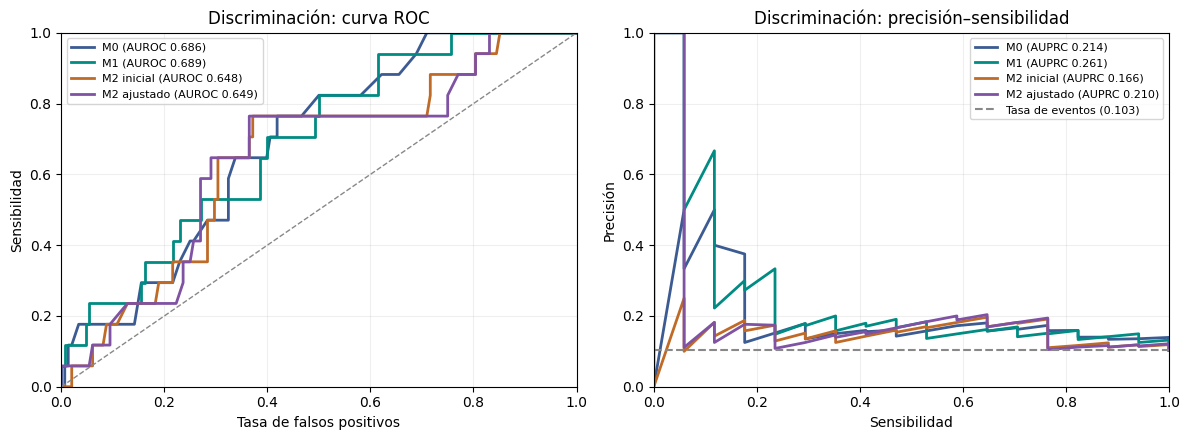

In [16]:
colors = {
    "M0": "#3b5b92", "M1": "#008b83",
    "M2 inicial": "#bf6b27", "M2 ajustado": "#7f52a3",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probabilities in test_probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[0].plot(false_positive_rate, true_positive_rate,
                 label=f"{name} (AUROC {test_metrics[name]['AUROC']:.3f})",
                 color=colors[name], linewidth=2)
    axes[1].plot(recall, precision,
                 label=f"{name} (AUPRC {test_metrics[name]['AUPRC (AP)']:.3f})",
                 color=colors[name], linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="#888888", linewidth=1)
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad",
            title="Discriminación: curva ROC", xlim=(0, 1), ylim=(0, 1))
axes[1].axhline(y_test.mean(), linestyle="--", color="#888888",
                label=f"Tasa de eventos ({y_test.mean():.3f})")
axes[1].set(xlabel="Sensibilidad", ylabel="Precisión",
            title="Discriminación: precisión–sensibilidad", xlim=(0, 1), ylim=(0, 1))
for axis in axes:
    axis.legend(loc="best", fontsize=8)
    axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**Interpretación.** M1 tiene la mayor AUROC (0,6888) y AUPRC (0,2615) en prueba. M2 ajustado aumenta la AUPRC respecto al M2 inicial (0,2102 frente a 0,1658), pero ambos quedan por debajo de las regresiones logísticas en AUROC y AUPRC. La línea horizontal de la derecha marca la tasa de eventos (0,1030); todos los modelos la superan en AUPRC. Los saltos de precisión–sensibilidad reflejan que solo existen **17 casos positivos**: no se deben interpretar diferencias pequeñas entre trazos como superioridad estable.

### Calibración exploratoria

Se agrupan las probabilidades de cada modelo en **tres grupos de tamaño aproximadamente igual**. Para cada grupo se compara la probabilidad media predicha con la proporción observada de readmisión. Se muestran los tamaños y eventos de cada grupo para no ocultar la escasez de información. La diagonal indica concordancia perfecta.

La curva es **exploratoria**: con 17 eventos, cada punto puede depender de muy pocos casos y los grupos varían entre modelos. Brier cuantifica error global, pero no demuestra por sí solo buena calibración. No se ajusta ninguna función de calibración al prueba.

Pacientes  Eventos  Probabilidad media  \
Modelo      Grupo                                           
M0          1             55        2              0.0497   
            2             58        7              0.0984   
            3             52        8              0.1707   
M1          1             55        1              0.0409   
            2             55        7              0.0942   
            3             55        9              0.2000   
M2 inicial  1             55        4              0.0518   
            2             56        4              0.1002   
            3             54        9              0.1829   
M2 ajustado 1             55        4              0.0648   
            2             55        2              0.0974   
            3             55       11              0.1621   

                   Frecuencia observada  
Modelo      Grupo                        
M0          1                    0.0364  
            2                    0.1207  
            3                    0.1538  
M1          1                    0.0182  
            2                    0.1273  
            3                    0.1636  
M2 inicial  1                    0.0727  
            2                    0.0714  
            3                    0.1667  
M2 ajustado 1                    0.0727  
            2                    0.0364  
            3                    0.2000

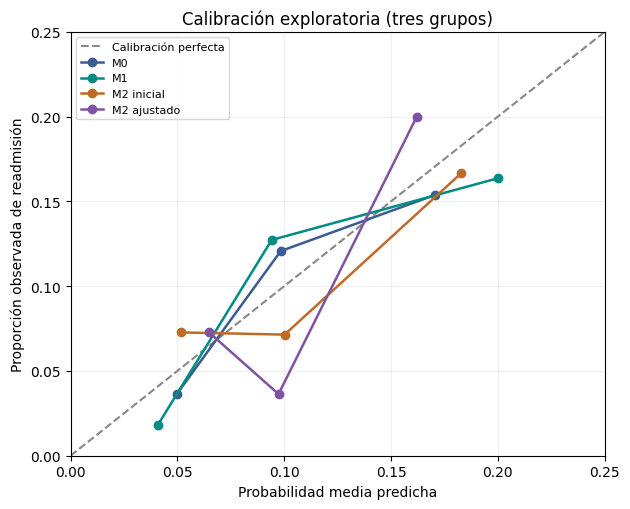

In [17]:
calibration_rows = []
for name, probabilities in test_probabilities.items():
    # Los rangos separan probabilidades predichas; no reentrenan el modelo.
    groups = pd.qcut(pd.Series(probabilities), q=3, labels=False, duplicates="drop")
    for group in sorted(groups.dropna().unique()):
        mask = groups.eq(group).to_numpy()
        calibration_rows.append({
            "Modelo": name,
            "Grupo": int(group) + 1,
            "Pacientes": int(mask.sum()),
            "Eventos": int(y_test.to_numpy()[mask].sum()),
            "Probabilidad media": float(probabilities[mask].mean()),
            "Frecuencia observada": float(y_test.to_numpy()[mask].mean()),
        })
calibration_table = pd.DataFrame(calibration_rows).set_index(["Modelo", "Grupo"])
display(calibration_table.round(4))

fig, axis = plt.subplots(figsize=(6.4, 5.2))
axis.plot([0, 1], [0, 1], linestyle="--", color="#888888",
          label="Calibración perfecta")
for name in test_probabilities:
    rows = calibration_table.loc[name]
    axis.plot(rows["Probabilidad media"], rows["Frecuencia observada"],
              marker="o", linewidth=1.8, label=name, color=colors[name])
axis.set(xlabel="Probabilidad media predicha",
         ylabel="Proporción observada de readmisión",
         title="Calibración exploratoria (tres grupos)",
         xlim=(0, 0.25), ylim=(0, 0.25))
axis.legend(fontsize=8)
axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**Interpretación.** En el grupo de mayor probabilidad de M1, la predicción media es 0,2000 y la frecuencia observada 0,1636 (**9 eventos entre 55 pacientes**). Para M2 ajustado, el grupo alto predice 0,1621 y observa 0,2000 (**11/55**). Estas coincidencias o diferencias son inestables porque cada grupo contiene pocos eventos y los grupos no abarcan exactamente los mismos pacientes entre modelos. La figura amplía el rango 0–0,25 para mostrar los puntos; no realiza una recalibración ni justifica uso clínico.

## 10. Interpretabilidad global de M2 ajustado con SHAP

SHAP descompone la salida del **XGBoost ajustado** en contribuciones de las seis variables. La gráfica de barras resume la **media del valor absoluto** de cada contribución; la gráfica de distribución muestra su variación entre los pacientes de prueba y el valor de cada variable en sus unidades originales para la escala de color. Las contribuciones se calcularon sobre los valores transformados por el flujo de modelado. Se utilizan nombres legibles, pero se conservan las seis variables del protocolo. El sexo se representa como el indicador `M` frente a `F`.

Con `TreeExplainer` en la salida `raw` de clasificación binaria, las contribuciones son **escala logit**, no cambios directos de probabilidad. Los valores mayores o menores describen cómo se mueve la predicción del modelo respecto a su valor base. SHAP explica el modelo entrenado en esta muestra; **no prueba efectos causales**, importancia clínica ni estabilidad de las atribuciones en otra población. La visualización de prueba es posterior al ajuste y no cambia el modelo.

In [18]:
preprocessor_final = model_m2_tuned.named_steps["preprocessor"]
X_test_processed = preprocessor_final.transform(X_test[M1_FEATURES])
assert X_test_processed.shape == (len(X_test), 6)

feature_labels = [
    "Edad (años)",
    "Hospitalizaciones previas (180 d)",
    "Diagnósticos distintos (180 d)",
    "Medicamentos distintos (180 d)",
    "Mediciones (180 d)",
    "Sexo: M frente a F",
]
feature_values = X_test[NUMERIC_FEATURES].copy()
feature_values["sex_M"] = X_test["sex"].eq("M").astype(int)
feature_values.columns = feature_labels

explainer = shap.TreeExplainer(model_m2_tuned.named_steps["classifier"],
                               model_output="raw")
raw_explanation = explainer(X_test_processed)
assert raw_explanation.values.shape == (len(X_test), len(feature_labels))
explanation = shap.Explanation(
    values=raw_explanation.values,
    base_values=raw_explanation.base_values,
    data=feature_values.to_numpy(),
    feature_names=feature_labels,
)
mean_abs_shap = pd.Series(
    np.abs(explanation.values).mean(axis=0),
    index=feature_labels,
    name="Media de |SHAP| (escala logit)",
).sort_values(ascending=False)
display(mean_abs_shap.to_frame().round(4))

,Media de |SHAP| (escala logit)
Sexo: M frente a F,0.3484
Diagnósticos distintos (180 d),0.1759
Mediciones (180 d),0.0403
Edad (años),0.0272
Medicamentos distintos (180 d),0.0151
Hospitalizaciones previas (180 d),0.0000


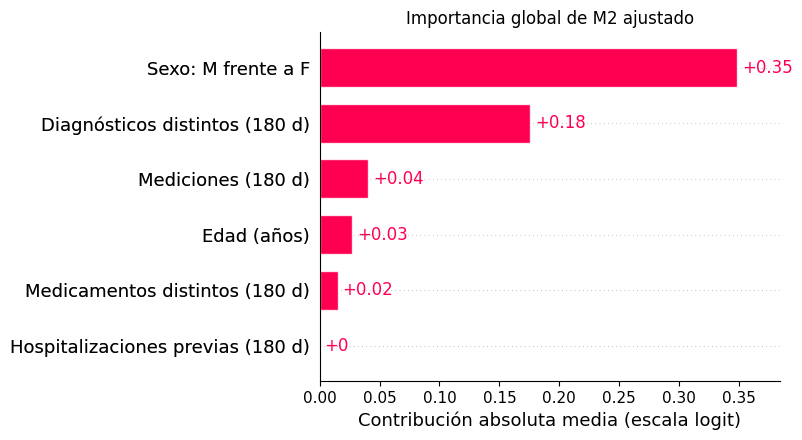

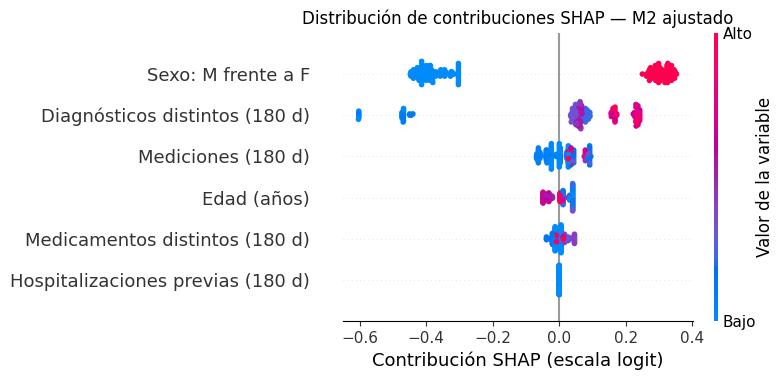

In [19]:
plt.figure(figsize=(8, 4.8))
shap.plots.bar(explanation, max_display=6, show=False)
plt.title("Importancia global de M2 ajustado")
plt.xlabel("Contribución absoluta media (escala logit)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5.2))
shap.plots.beeswarm(explanation, max_display=6, show=False,
                    color_bar_label="Valor de la variable")
color_axis = plt.gcf().axes[-1]
color_ticks = color_axis.get_yticks()
assert len(color_ticks) == 2
color_axis.set_yticks(color_ticks, labels=["Bajo", "Alto"])
plt.title("Distribución de contribuciones SHAP — M2 ajustado")
plt.xlabel("Contribución SHAP (escala logit)")
plt.tight_layout()
plt.show()

**Interpretación.** En M2 ajustado, `sex` (indicador M frente a F, media |SHAP| **0,3484**) y `distinct_diagnoses_180d` (**0,1759**) dominan la importancia media en los pacientes de prueba. `prior_inpatient_hospitalizations_180d` tiene contribución media nula en este modelo. En la distribución, el valor M del indicador aparece con contribuciones positivas y F con negativas respecto al valor base, mientras que las contribuciones de diagnósticos varían entre personas. Esto describe **cómo predice este XGBoost concreto**: la importancia de sexo puede reflejar patrones del generador de datos sintéticos o correlaciones y no un mecanismo causal. Las contribuciones están en escala logit, no en puntos porcentuales de riesgo.

## 11. Conclusiones y límites

**Resultado en prueba.** M1 ofrece la mayor discriminación observada (AUROC **0,6888**, AUPRC **0,2615**), mientras M0 tiene el menor error de probabilidad (Brier **0,0873**). M2 inicial obtiene **0,6484 / 0,1658 / 0,0895** (AUROC/AUPRC/Brier). M2 ajustado obtiene **0,6494 / 0,2102 / 0,0890**: en esta ejecución mejora la AUPRC y reduce ligeramente el Brier respecto al M2 inicial, pero ambos XGBoost quedan por detrás de M0 y M1 en discriminación en esta partición. Las métricas describen los modelos fijados en entrenamiento; no se usaron para volver a elegir hiperparámetros.

La historia clínica añadida a M0 mejora AUROC y AUPRC en los cinco pliegues de entrenamiento y en este prueba, aunque **no mejora el Brier de prueba**. Esto apoya una señal predictiva exploratoria, sin probar superioridad estadística. La mayor flexibilidad de XGBoost puede ser difícil de estimar con solo **68 eventos de entrenamiento**; el espacio acotado de Optuna y las variables sintéticas también condicionan el resultado. No se ajustó el modelo en respuesta a las métricas de prueba.

**Límites.** El prueba tiene únicamente **17 eventos** y no se calculan intervalos de confianza ni pruebas de significancia. M2 ajustado fue seleccionado con los mismos pliegues que se reportan, por lo que sus medias de validación no son una estimación independiente. La calibración se examina con tres grupos muy pequeños y no hay calibración formal ni validación externa. Los pacientes son sintéticos y el mapeo OMOP es mínimo; las atribuciones SHAP explican predicciones, no efectos causales. El desempeño observado no demuestra utilidad clínica ni permite extrapolación a pacientes reales.